# Bài 3. Phát hiện biên và phân ngưỡng

**Nội dung:** (1) Sobel, Laplacian (LoG), Canny và khảo sát tham số; (2) phân ngưỡng cố định, Otsu (tự lập trình,
đối chiếu OpenCV / scikit-image) và adaptive thresholding; (3) ảnh hưởng của nhiễu (Gaussian, muối-tiêu) đến phát
hiện biên và phân ngưỡng.

**Ảnh đầu vào:** `camera.png` (512×512, xám, ảnh mẫu scikit-image) cho phát hiện biên; `coins.png` (303×384) cho
ngưỡng cố định/Otsu; `page.png` (191×384, trang chữ có chiếu sáng không đều) cho adaptive thresholding.

In [1]:
# ===== Cài đặt & hàm tiện ích dùng chung =====
import os, time, warnings
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data, color, filters, morphology, measure, segmentation, util
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 80, "font.size": 9, "axes.titlesize": 9})

# Thư mục ảnh đầu vào / kết quả.
# Muốn dùng ảnh trong bộ dữ liệu LMS: chép ảnh vào images/ và đổi tên file ở ô "Ảnh đầu vào".
IMG_DIR, OUT_DIR = "images", "outputs/bai3"
for d in (IMG_DIR, OUT_DIR):
    os.makedirs(d, exist_ok=True)


def load_rgb(name, fallback, max_side=None):
    """Đọc ảnh màu RGB từ images/<name>; nếu chưa có thì lấy ảnh mẫu rồi lưu lại."""
    p = os.path.join(IMG_DIR, name)
    if not os.path.exists(p):
        cv2.imwrite(p, cv2.cvtColor(fallback(), cv2.COLOR_RGB2BGR))
    img = cv2.cvtColor(cv2.imread(p, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    if max_side and max(img.shape[:2]) > max_side:
        s = max_side / max(img.shape[:2])
        img = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    return img


def load_gray(name, fallback, max_side=None):
    """Đọc ảnh xám uint8 từ images/<name>; nếu chưa có thì lấy ảnh mẫu rồi lưu lại."""
    p = os.path.join(IMG_DIR, name)
    if not os.path.exists(p):
        cv2.imwrite(p, fallback())
    img = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    if max_side and max(img.shape) > max_side:
        s = max_side / max(img.shape)
        img = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    return img


def show(images, titles=None, ncols=4, name=None, cell=3.0, cmap="gray"):
    """Hiển thị lưới ảnh; ảnh 2-D hiển thị theo thang xám cố định; lưu vào OUT_DIR/name."""
    n = len(images)
    ncols = min(ncols, n)
    nrows = int(np.ceil(n / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(cell * ncols, (cell * images[0].shape[0] / images[0].shape[1] + 0.35) * nrows), squeeze=False)
    for i, ax in enumerate(axs.ravel()):
        ax.axis("off")
        if i >= n:
            continue
        im = images[i]
        if im.ndim == 2:
            if im.dtype == np.uint8:
                ax.imshow(im, cmap=cmap, vmin=0, vmax=255)
            elif im.dtype == bool:
                ax.imshow(im, cmap=cmap, vmin=0, vmax=1)
            else:
                ax.imshow(im, cmap=cmap)
        else:
            ax.imshow(im)
        if titles is not None:
            ax.set_title(titles[i])
    fig.tight_layout()
    if name:
        fig.savefig(os.path.join(OUT_DIR, name), dpi=110, bbox_inches="tight")
    plt.show()


## 3.0 Ảnh đầu vào

camera: (512, 512) | coins: (303, 384) | page: (191, 384)


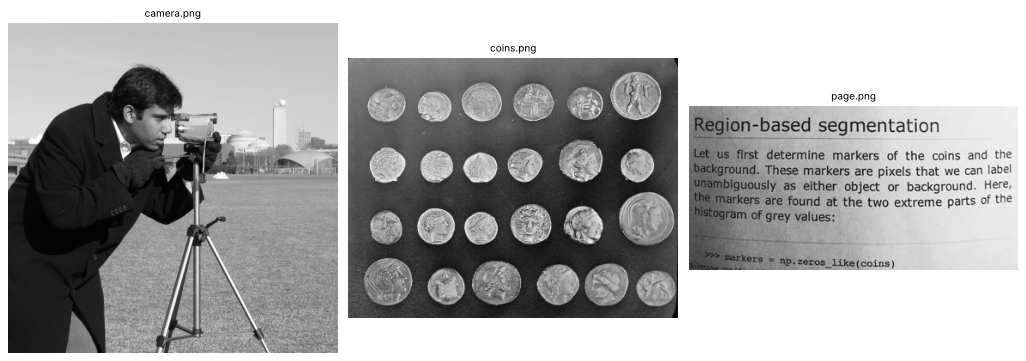

In [2]:
cam = load_gray("camera.png", data.camera)
coins = load_gray("coins.png", data.coins)
page = load_gray("page.png", data.page)
print("camera:", cam.shape, "| coins:", coins.shape, "| page:", page.shape)
show([cam, coins, page], ["camera.png", "coins.png", "page.png"], ncols=3, cell=4.3, name="b3_input.png")

## 3.1 Phát hiện biên: Sobel, Laplacian, Canny

### Sobel
Gradient theo $x$, $y$ bằng nhân chập Sobel; độ lớn $|\nabla f|=\sqrt{G_x^2+G_y^2}$. Cài đặt bằng `cv2.filter2D` với
nhân Sobel tự định nghĩa rồi đối chiếu `cv2.Sobel`.
**Tham số khảo sát:** kích thước nhân `ksize` ∈ {3, 5, 7}; làm trơn Gaussian trước (σ ∈ {0, 1, 2}); ngưỡng nhị phân hóa độ lớn gradient.

Sobel tự lập (filter2D) so với cv2.Sobel: sai khác lớn nhất = 0.0


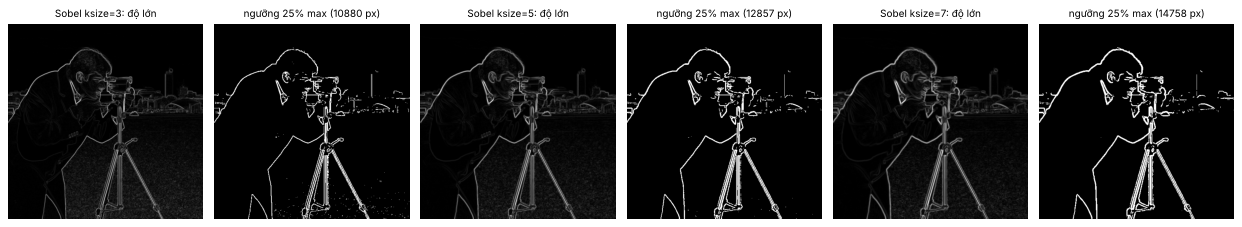

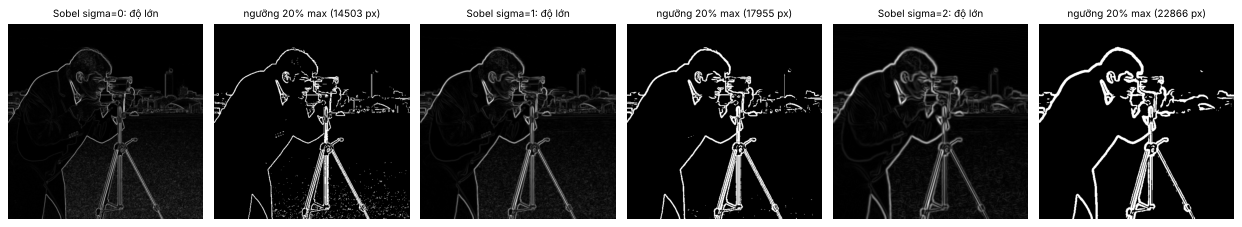

In [3]:
Kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
Ky = Kx.T
f = cam.astype(np.float32)
gx = cv2.filter2D(f, -1, Kx, borderType=cv2.BORDER_REFLECT_101)
gy = cv2.filter2D(f, -1, Ky, borderType=cv2.BORDER_REFLECT_101)
mag_mine = np.hypot(gx, gy)
mag_cv = np.hypot(cv2.Sobel(f, cv2.CV_32F, 1, 0, ksize=3), cv2.Sobel(f, cv2.CV_32F, 0, 1, ksize=3))
print("Sobel tự lập (filter2D) so với cv2.Sobel: sai khác lớn nhất =", float(np.abs(mag_mine - mag_cv).max()))

def sobel_mag(img, ksize=3, sigma=0):
    g = cv2.GaussianBlur(img, (0, 0), sigma) if sigma > 0 else img
    g = g.astype(np.float32)
    return np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=ksize), cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=ksize))

def norm8(m):
    return np.clip(m / m.max() * 255, 0, 255).astype(np.uint8)

# (a) ảnh hưởng ksize (không làm trơn)
imgs, tits = [], []
for k in (3, 5, 7):
    m = sobel_mag(cam, k)
    imgs += [norm8(m), (m > 0.25 * m.max()).astype(np.uint8) * 255]
    tits += [f"Sobel ksize={k}: độ lớn", f"ngưỡng 25% max ({int((m > 0.25 * m.max()).sum())} px)"]
show(imgs, tits, ncols=6, cell=2.6, name="b3_sobel_ksize.png")

# (b) ảnh hưởng làm trơn Gaussian (ksize=3), ngưỡng cố định theo % của giá trị max
imgs, tits = [], []
for sg in (0, 1, 2):
    m = sobel_mag(cam, 3, sg)
    e = (m > 0.2 * m.max())
    imgs += [norm8(m), e]
    tits += [f"Sobel sigma={sg}: độ lớn", f"ngưỡng 20% max ({int(e.sum())} px)"]
show(imgs, tits, ncols=6, cell=2.6, name="b3_sobel_sigma.png")

### Laplacian / LoG
Laplacian là đạo hàm bậc hai (nhạy nhiễu) nên thường làm trơn Gaussian trước -> **LoG**. Biên là các điểm **zero-crossing**
(đổi dấu) với biên độ đủ lớn.
**Tham số khảo sát:** `ksize` của `cv2.Laplacian` ∈ {1, 3, 5}; σ của LoG ∈ {1, 2, 3}; ngưỡng zero-crossing.

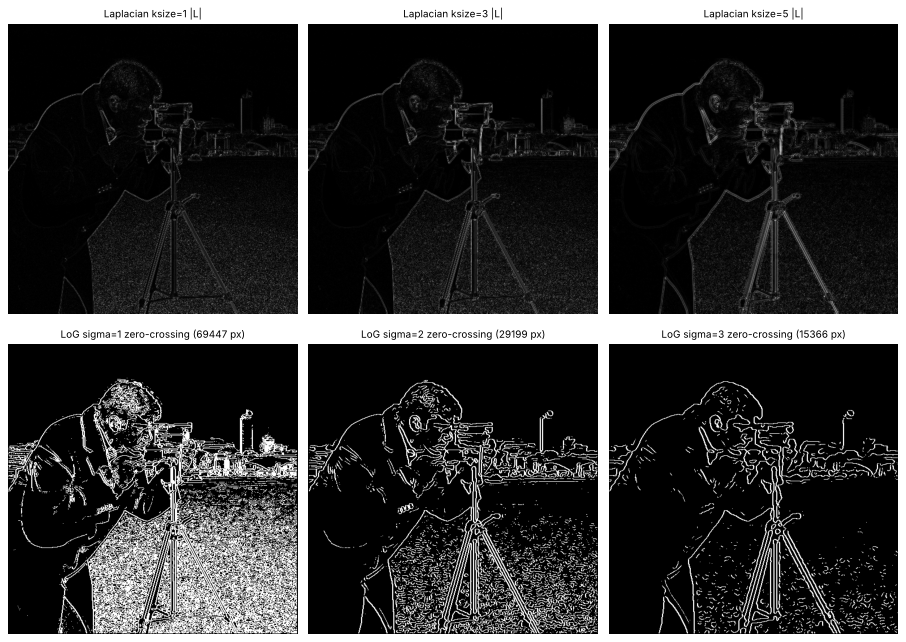

In [4]:
def zero_crossing(L, thr):
    """Điểm đổi dấu giữa láng giềng (ngang/dọc/chéo) và chênh biên độ > thr (dịch ảnh bằng np.roll)."""
    zc = np.zeros(L.shape, bool)
    for dy, dx in [(0, 1), (1, 0), (1, 1), (1, -1)]:
        b = np.roll(L, (-dy, -dx), axis=(0, 1))
        zc |= ((L * b) < 0) & (np.abs(L - b) > thr)
    zc[0, :] = zc[-1, :] = False
    zc[:, 0] = zc[:, -1] = False
    return zc

# (a) cv2.Laplacian với các ksize (ảnh gốc, không làm trơn)
imgs, tits = [], []
for k in (1, 3, 5):
    L = cv2.Laplacian(cam.astype(np.float32), cv2.CV_32F, ksize=k)
    imgs += [norm8(np.abs(L))]
    tits += [f"Laplacian ksize={k} |L|"]
# (b) LoG với các sigma: làm trơn Gaussian rồi Laplacian + zero-crossing
for sg in (1, 2, 3):
    g = cv2.GaussianBlur(cam.astype(np.float32), (0, 0), sg)
    L = cv2.Laplacian(g, cv2.CV_32F, ksize=3)
    zc = zero_crossing(L, 0.04 * np.abs(L).max())
    imgs += [zc]
    tits += [f"LoG sigma={sg} zero-crossing ({int(zc.sum())} px)"]
show(imgs, tits, ncols=3, cell=3.8, name="b3_laplacian.png")

### Canny
Làm trơn Gaussian -> gradient -> non-maximum suppression -> ngưỡng kép (`low`, `high`) và liên kết biên theo độ trễ.
**Tham số khảo sát:** (low, high) ∈ {(20,60), (50,150), (100,200), (150,250)}; σ làm trơn ∈ {0, 1, 2, 3};
`apertureSize` ∈ {3, 5}; `L2gradient`.

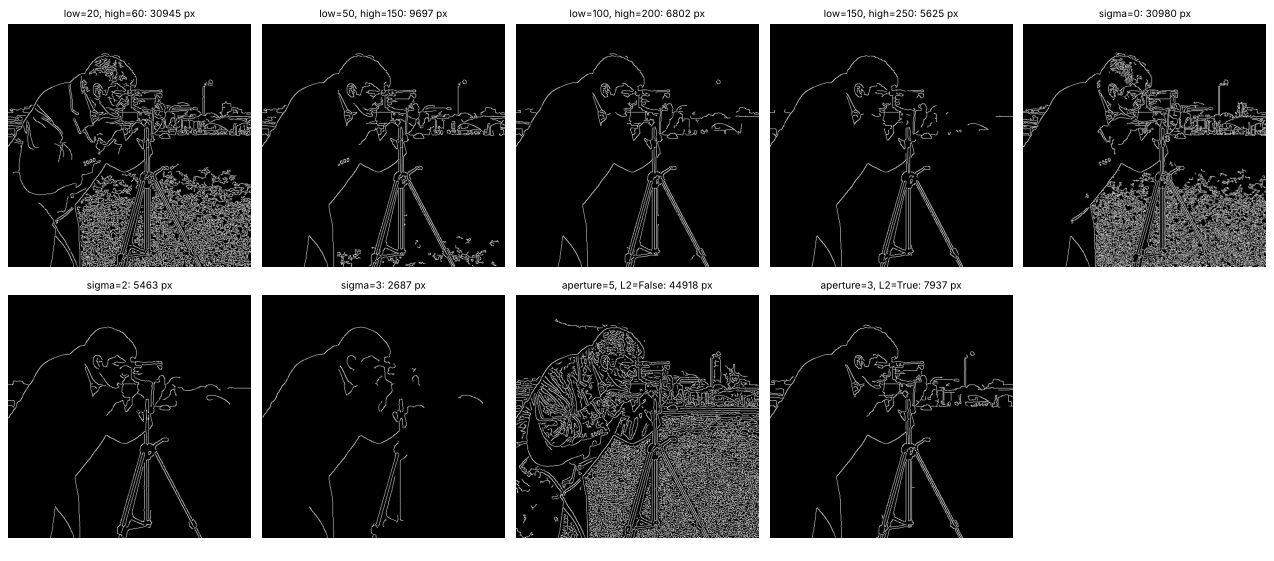

In [5]:
def canny(img, lo, hi, sigma=0, ap=3, l2=False):
    g = cv2.GaussianBlur(img, (0, 0), sigma) if sigma > 0 else img
    return cv2.Canny(g, lo, hi, apertureSize=ap, L2gradient=l2)

# (a) ngưỡng (low, high), sigma = 1
pairs = [(20, 60), (50, 150), (100, 200), (150, 250)]
imgs = [canny(cam, lo, hi, 1) for lo, hi in pairs]
tits = [f"low={lo}, high={hi}: {int((e > 0).sum())} px" for (lo, hi), e in zip(pairs, imgs)]
# (b) sigma, ngưỡng (50, 150)
for sg in (0, 2, 3):
    e = canny(cam, 50, 150, sg)
    imgs.append(e); tits.append(f"sigma={sg}: {int((e > 0).sum())} px")
# (c) apertureSize / L2gradient
for ap, l2 in [(5, False), (3, True)]:
    e = canny(cam, 50, 150, 1, ap, l2)
    imgs.append(e); tits.append(f"aperture={ap}, L2={l2}: {int((e > 0).sum())} px")
show(imgs, tits, ncols=5, cell=3.2, name="b3_canny_params.png")

### So sánh ba bộ dò biên trên cùng ảnh
Sobel (σ=1, ngưỡng 20% max), LoG (σ=2) và Canny (σ=1, 50/150).

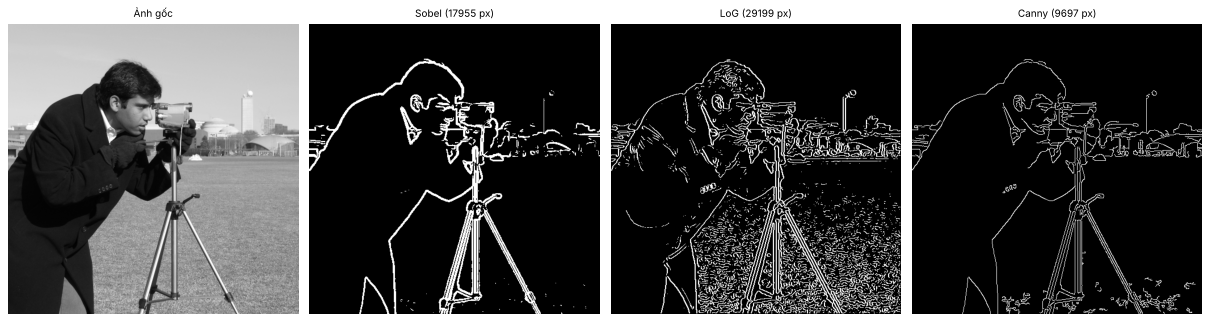

In [6]:
m = sobel_mag(cam, 3, 1)
e_sobel = m > 0.2 * m.max()
g2 = cv2.GaussianBlur(cam.astype(np.float32), (0, 0), 2)
L2 = cv2.Laplacian(g2, cv2.CV_32F, ksize=3)
e_log = zero_crossing(L2, 0.04 * np.abs(L2).max())
e_canny = canny(cam, 50, 150, 1) > 0
show([cam, e_sobel, e_log, e_canny],
     ["Ảnh gốc", f"Sobel ({int(e_sobel.sum())} px)", f"LoG ({int(e_log.sum())} px)", f"Canny ({int(e_canny.sum())} px)"],
     ncols=4, cell=3.8, name="b3_edge_compare.png")

**Nhận xét 3.1**
* **Sobel:** cài đặt bằng `filter2D` trùng hoàn toàn `cv2.Sobel` (sai khác lớn nhất 0,0). Tăng `ksize` 3 -> 5 -> 7 (ngưỡng 25% max) làm số điểm biên tăng 10 880 -> 12 857 -> 14 758 và biên dày hơn; nhiễu hạt trên bãi cỏ giảm vì nhân lớn tự làm trơn, nhưng chi tiết nhỏ (tòa nhà xa) bị nhòe. Làm trơn Gaussian trước (σ = 0, 1, 2; ngưỡng 20% max): 14 503 -> 17 955 -> 22 866 điểm; hạt cỏ biến mất nhưng đường biên to bè, định vị kém. Sobel luôn cho biên *dày* nhiều pixel và phụ thuộc ngưỡng chọn tay.
* **Laplacian / LoG:** `cv2.Laplacian` trên ảnh gốc gần như chỉ thấy nhiễu hạt vì đạo hàm bậc hai khuếch đại nhiễu. LoG + zero-crossing: σ = 1, 2, 3 cho 69 447, 29 199, 15 366 điểm - σ tăng thì biên liền mạch, bớt nhiễu nhưng mất chi tiết. Ưu điểm là biên mảnh và khép kín; nhược điểm là sinh nhiều biên giả ở vùng phẳng (cỏ) và không cho biết hướng/độ mạnh biên.
* **Canny:** số điểm biên giảm dần khi tăng ngưỡng (low/high) 20/60 -> 50/150 -> 100/200 -> 150/250: 30 945 -> 9 697 -> 6 802 -> 5 625; ngưỡng thấp lấy cả kết cấu cỏ, ngưỡng cao chỉ giữ biên chính nhưng bắt đầu làm đứt đường chân trời. σ = 0, 1, 2, 3 (ngưỡng 50/150): 30 980, 9 697, 5 463, 2 687 điểm - σ lớn tạo biên sạch nhưng mất chi tiết nhỏ. `apertureSize = 5` cho 44 918 điểm vì đạo hàm nhân lớn không chuẩn hóa có biên độ lớn hơn nên cùng ngưỡng sẽ lọt nhiều điểm hơn; `L2gradient = True` cho 7 937 điểm (ít hơn) do độ lớn L2 ≤ L1.
* **So sánh:** Canny cho biên mảnh 1 px, liên tục, ít biên giả nhất (NMS + ngưỡng trễ); Sobel dày; LoG khép kín nhưng nhiều biên giả. Cùng một ảnh: Sobel (σ=1) 17 955, LoG (σ=2) 29 199, Canny (σ=1, 50/150) 9 697 điểm.

## 3.2 Phân ngưỡng: cố định, Otsu, adaptive

### Ngưỡng cố định
Khảo sát $T\in\{60,107,150\}$ trên `coins.png` (107 xấp xỉ ngưỡng Otsu).

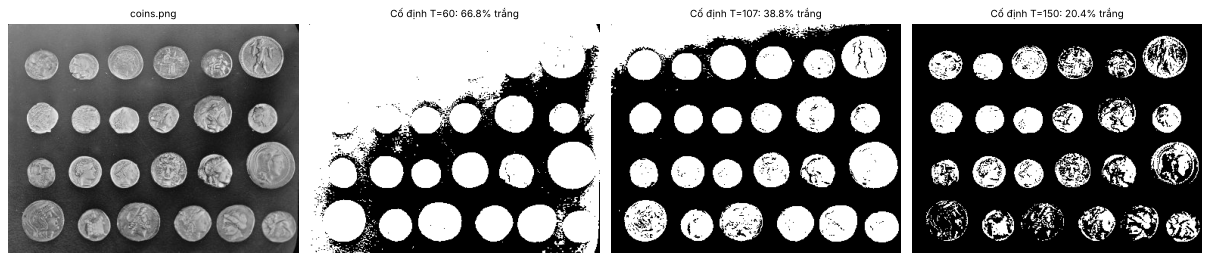

In [7]:
imgs, tits = [coins], ["coins.png"]
for T in (60, 107, 150):
    _, b = cv2.threshold(coins, T, 255, cv2.THRESH_BINARY)
    imgs.append(b); tits.append(f"Cố định T={T}: {100 * (b > 0).mean():.1f}% trắng")
show(imgs, tits, ncols=4, cell=3.8, name="b3_fixed.png")

### Otsu - tự lập trình
Chọn $T$ cực đại phương sai giữa hai lớp: $\sigma_B^2(T)=\dfrac{(\mu_T\,\omega(T)-\mu(T))^2}{\omega(T)\,(1-\omega(T))}$
với $\omega(T)=\sum_{i\le T}p_i$, $\mu(T)=\sum_{i\le T}i\,p_i$, $\mu_T=\mu(255)$. So sánh với `cv2.THRESH_OTSU` và `skimage.filters.threshold_otsu`.

ảnh         Otsu tự lập   OpenCV   skimage    điểm khác biệt (tự lập vs OpenCV)
coins               107      107     107.0                                    0
camera              102      102     102.0                                    0
page                157      157     157.0                                    0


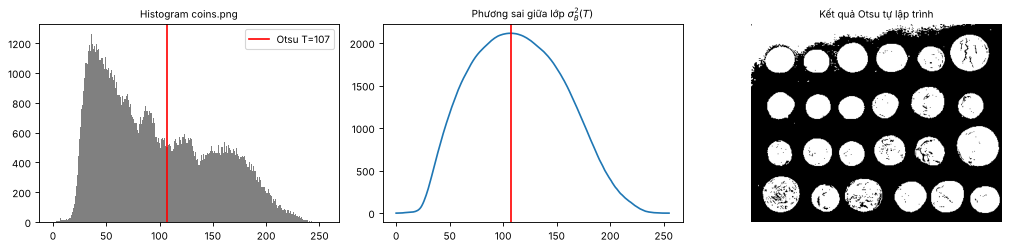

In [8]:
def otsu_threshold(img):
    hist = np.bincount(img.ravel(), minlength=256).astype(np.float64)
    p = hist / hist.sum()
    omega = np.cumsum(p)                       # xác suất lớp nền (<= T)
    mu = np.cumsum(p * np.arange(256))         # trung bình tích lũy
    mu_t = mu[-1]
    denom = omega * (1 - omega)
    sigma_b2 = np.zeros(256)
    ok = denom > 1e-12
    sigma_b2[ok] = (mu_t * omega[ok] - mu[ok]) ** 2 / denom[ok]
    return int(np.argmax(sigma_b2)), sigma_b2

print(f"{'ảnh':10s} {'Otsu tự lập':>12s} {'OpenCV':>8s} {'skimage':>9s} {'điểm khác biệt (tự lập vs OpenCV)':>36s}")
for name, im in [("coins", coins), ("camera", cam), ("page", page)]:
    t_my, _ = otsu_threshold(im)
    t_cv, b_cv = cv2.threshold(im, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    t_sk = filters.threshold_otsu(im)
    _, b_my = cv2.threshold(im, t_my, 255, cv2.THRESH_BINARY)
    print(f"{name:10s} {t_my:12d} {int(t_cv):8d} {t_sk:9.1f} {int((b_my != b_cv).sum()):36d}")

t_my, sb2 = otsu_threshold(coins)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].bar(range(256), np.bincount(coins.ravel(), minlength=256), width=1.0, color="gray")
ax[0].axvline(t_my, color="r", label=f"Otsu T={t_my}"); ax[0].set_title("Histogram coins.png"); ax[0].legend()
ax[1].plot(sb2); ax[1].axvline(t_my, color="r"); ax[1].set_title(r"Phương sai giữa lớp $\sigma_B^2(T)$")
ax[2].imshow(cv2.threshold(coins, t_my, 255, cv2.THRESH_BINARY)[1], cmap="gray"); ax[2].set_title("Kết quả Otsu tự lập trình"); ax[2].axis("off")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "b3_otsu.png"), dpi=110, bbox_inches="tight"); plt.show()

### Adaptive thresholding
Ngưỡng cục bộ $T(x,y)=\text{mean/gauss}_{\text{block}}(x,y)-C$. Ảnh `page.png` chiếu sáng không đều: so sánh với Otsu toàn cục.
**Tham số khảo sát:** `blockSize` ∈ {11, 31, 101}, `C` ∈ {2, 10}, phương pháp MEAN / GAUSSIAN.

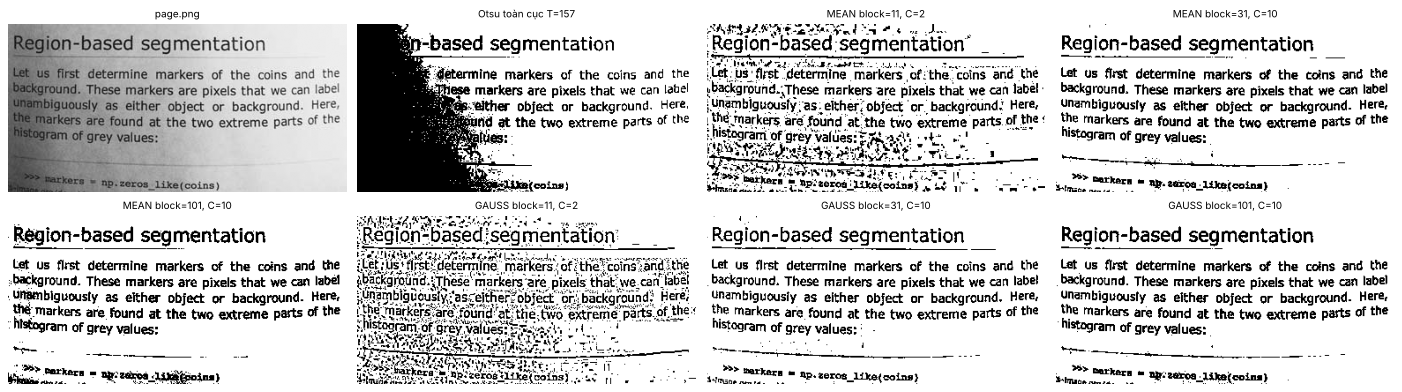

In [9]:
t_p, _ = otsu_threshold(page)
imgs = [page, cv2.threshold(page, t_p, 255, cv2.THRESH_BINARY)[1]]
tits = ["page.png", f"Otsu toàn cục T={t_p}"]
for meth, mn in [(cv2.ADAPTIVE_THRESH_MEAN_C, "MEAN"), (cv2.ADAPTIVE_THRESH_GAUSSIAN_C, "GAUSS")]:
    for bs, C in [(11, 2), (31, 10), (101, 10)]:
        imgs.append(cv2.adaptiveThreshold(page, 255, meth, cv2.THRESH_BINARY, bs, C))
        tits.append(f"{mn} block={bs}, C={C}")
show(imgs, tits, ncols=4, cell=4.4, name="b3_adaptive.png")

**Nhận xét 3.2**
* **Ngưỡng cố định** (coins): T = 60 làm 66,8% pixel thành trắng - nền sáng ở góc trên bị gộp vào đối tượng; T = 150 chỉ còn 20,4%, đồng xu chỉ còn các mảng sáng và bị thủng nhiều; T = 107 (≈ Otsu, 38,8%) tách tốt nhất, nhưng vùng nền ở góc trên vẫn dính vào do chiếu sáng không đều. Ngưỡng cố định phải chọn tay và chỉ đúng với một điều kiện chiếu sáng.
* **Otsu tự lập trình** trùng tuyệt đối với OpenCV và scikit-image: coins T = 107, camera T = 102, page T = 157, số pixel khác biệt giữa mặt nạ tự lập và OpenCV = 0. Histogram coins có hai đỉnh (nền tối, đồng xu sáng) nên Otsu hoạt động tốt. Với `page.png` (bị bóng/chiếu sáng không đều) Otsu **toàn cục** (T = 157) làm mất cả nửa trái của trang thành khối đen, chữ không đọc được.
* **Adaptive thresholding** giải quyết vấn đề này vì ngưỡng tính theo vùng lân cận. `blockSize` nhỏ (11) với C = 2 cho nhiễu hạt dày đặc ở nền và viền chữ bị vỡ, vì ngưỡng cục bộ bám theo nhiễu; `blockSize` 31 hoặc 101 với C = 10 cho chữ rõ, nền sạch (GAUSSIAN mượt hơn MEAN, MEAN 101 còn vệt ở mép trái/đáy). C lớn loại nhiễu nền nhưng có nguy cơ đứt nét mảnh. Adaptive không phù hợp khi vật thể lớn hơn cửa sổ: trên `coins.png` (block 31 < đường kính đồng xu) nó chỉ giữ hoa văn/cạnh, thân đồng xu bị rỗng (Dice với mặt nạ Otsu chỉ 0,78 ngay cả khi ảnh sạch).

## 3.3 Ảnh hưởng của nhiễu

Thêm nhiễu Gaussian ($\sigma_n$ = 10, 25, 50) và nhiễu muối-tiêu (2%, 5%) vào `camera.png` / `coins.png`.
* **Biên:** ảnh biên tham chiếu = Canny (σ=1, 50/150) trên ảnh sạch. Đo precision/recall/F1 với dung sai 1 px của các bộ dò:
  Sobel (ngưỡng 20% max), Canny không làm trơn, Canny σ=1.5, và Canny sau khử nhiễu (Gaussian 5×5 hoặc median 5).
* **Ngưỡng:** so với mặt nạ Otsu của ảnh sạch bằng Dice; theo dõi ngưỡng Otsu. So sánh Otsu, adaptive (block 31, C=10) và Otsu sau khử nhiễu.

nhiễu                     Sobel     Canny 50/150      Canny σ=1.5   Gauss5 + Canny  Median5 + Canny
sạch                      0.870            0.499            0.807            0.940            0.843   (F1)
Gauss σ=10                0.859            0.326            0.804            0.891            0.843   (F1)
Gauss σ=25                0.580            0.211            0.824            0.615            0.745   (F1)
Gauss σ=50                0.299            0.214            0.657            0.233            0.255   (F1)
Muối-tiêu 2%              0.560            0.342            0.808            0.690            0.845   (F1)
Muối-tiêu 5%              0.396            0.264            0.778            0.416            0.842   (F1)

Số điểm biên phát hiện (ảnh sạch có 9697 điểm tham chiếu):
sạch                      14503            30980             6505             9135             8221
Gauss σ=10                15754            54396             6504            10112             813

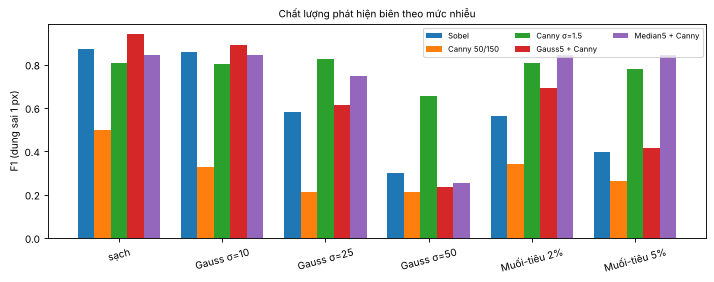

In [10]:
def add_gauss(img, sigma, seed=0):
    r = np.random.default_rng(seed)
    return np.clip(img.astype(np.float32) + r.normal(0, sigma, img.shape), 0, 255).astype(np.uint8)

def add_sp(img, amount, seed=0):
    r = np.random.default_rng(seed)
    o = img.copy(); u = r.random(img.shape)
    o[u < amount / 2] = 0; o[u > 1 - amount / 2] = 255
    return o

noises = {"sạch": lambda im: im,
          "Gauss σ=10": lambda im: add_gauss(im, 10), "Gauss σ=25": lambda im: add_gauss(im, 25), "Gauss σ=50": lambda im: add_gauss(im, 50),
          "Muối-tiêu 2%": lambda im: add_sp(im, 0.02), "Muối-tiêu 5%": lambda im: add_sp(im, 0.05)}

def edge_prf(pred, ref, tol=1):
    k = np.ones((2 * tol + 1, 2 * tol + 1), np.uint8)
    pred, ref = pred > 0, ref > 0
    ref_d, pred_d = cv2.dilate(ref.astype(np.uint8), k) > 0, cv2.dilate(pred.astype(np.uint8), k) > 0
    prec = (pred & ref_d).sum() / max(pred.sum(), 1)
    rec = (ref & pred_d).sum() / max(ref.sum(), 1)
    return prec, rec, 2 * prec * rec / max(prec + rec, 1e-9)

def sobel_edges(im):
    m = sobel_mag(im, 3, 0)
    return m > 0.2 * m.max()

detectors = {
    "Sobel":                lambda im: sobel_edges(im),
    "Canny 50/150":         lambda im: canny(im, 50, 150, 0),
    "Canny σ=1.5":          lambda im: canny(im, 50, 150, 1.5),
    "Gauss5 + Canny":       lambda im: canny(cv2.GaussianBlur(im, (5, 5), 0), 50, 150, 0),
    "Median5 + Canny":      lambda im: canny(cv2.medianBlur(im, 5), 50, 150, 0),
}
ref_edge = canny(cam, 50, 150, 1)
noisy_cam = {k: fn(cam) for k, fn in noises.items()}

rows = {}
print(f"{'nhiễu':14s} " + " ".join(f"{d:>16s}" for d in detectors))
for nk, nim in noisy_cam.items():
    row = []
    for dn, dfn in detectors.items():
        _, _, f1 = edge_prf(dfn(nim), ref_edge)
        row.append(f1)
    rows[nk] = row
    print(f"{nk:14s} " + " ".join(f"{v:16.3f}" for v in row) + "   (F1)")
print("\nSố điểm biên phát hiện (ảnh sạch có", int((ref_edge > 0).sum()), "điểm tham chiếu):")
for nk, nim in noisy_cam.items():
    print(f"{nk:14s} " + " ".join(f"{int((dfn(nim) > 0).sum()):16d}" for dfn in detectors.values()))

fig, ax = plt.subplots(figsize=(9, 3.6))
w = 0.16
for i, dn in enumerate(detectors):
    ax.bar(np.arange(len(noises)) + i * w, [rows[nk][i] for nk in noises], w, label=dn)
ax.set_xticks(np.arange(len(noises)) + 2 * w); ax.set_xticklabels(noises.keys(), rotation=15)
ax.set_ylabel("F1 (dung sai 1 px)"); ax.set_title("Chất lượng phát hiện biên theo mức nhiễu"); ax.legend(fontsize=7, ncol=3)
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "b3_noise_f1.png"), dpi=110, bbox_inches="tight"); plt.show()

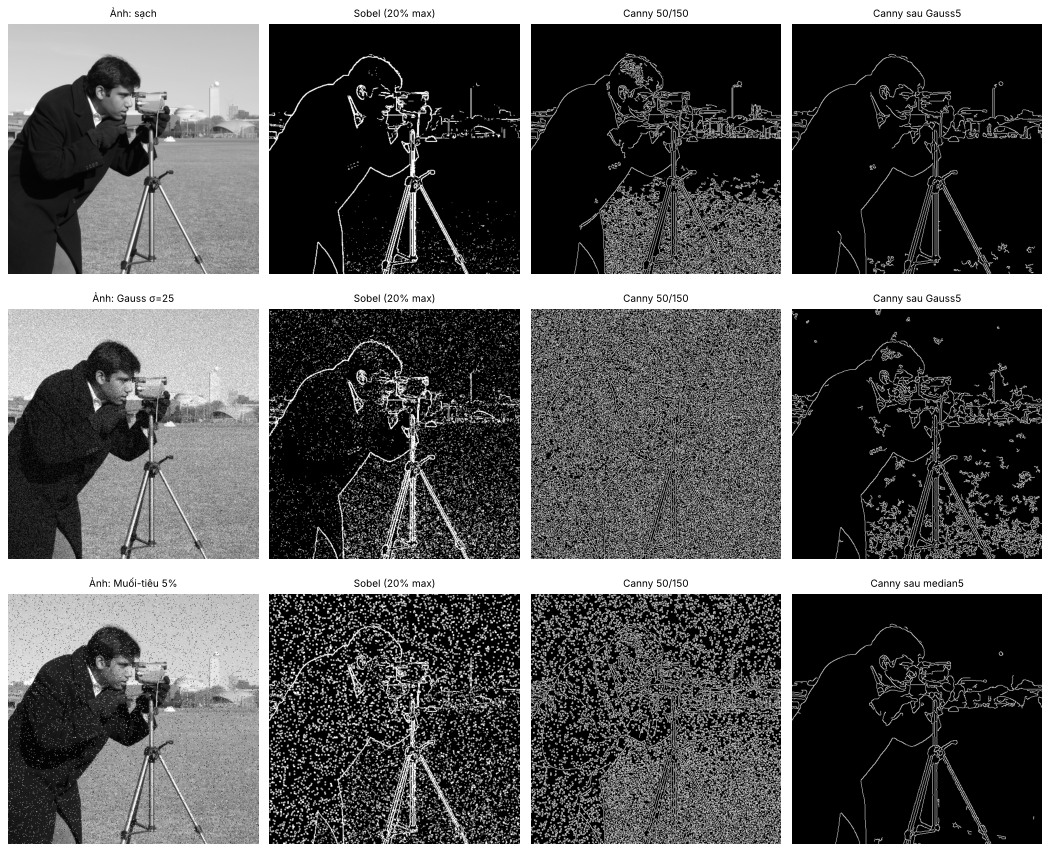

In [11]:
sel = ["sạch", "Gauss σ=25", "Muối-tiêu 5%"]
imgs, tits = [], []
for nk in sel:
    nim = noisy_cam[nk]
    imgs += [nim, sobel_edges(nim), canny(nim, 50, 150, 0), canny(cv2.medianBlur(nim, 5) if "Muối" in nk else cv2.GaussianBlur(nim, (5, 5), 0), 50, 150, 0)]
    tits += [f"Ảnh: {nk}", "Sobel (20% max)", "Canny 50/150", "Canny sau " + ("median5" if "Muối" in nk else "Gauss5")]
show(imgs, tits, ncols=4, cell=3.3, name="b3_noise_edges.png")

### Ảnh hưởng của nhiễu đến phân ngưỡng (coins.png)

Ngưỡng Otsu ảnh sạch = 107

nhiễu                            Otsu    Adaptive MEAN 31/10         Median5 + Otsu          Gauss5 + Otsu   (Dice so với mặt nạ Otsu ảnh sạch)
sạch                            1.000                  0.784                  0.967                  0.961   T_Otsu(thô) = 107
Gauss σ=10                      0.952                  0.764                  0.963                  0.959   T_Otsu(thô) = 106
Gauss σ=25                      0.875                  0.688                  0.945                  0.947   T_Otsu(thô) = 106
Gauss σ=50                      0.751                  0.603                  0.913                  0.919   T_Otsu(thô) = 106
Muối-tiêu 2%                    0.981                  0.778                  0.966                  0.951   T_Otsu(thô) = 108
Muối-tiêu 5%                    0.946                  0.767                  0.964                  0.940   T_Otsu(thô) = 111


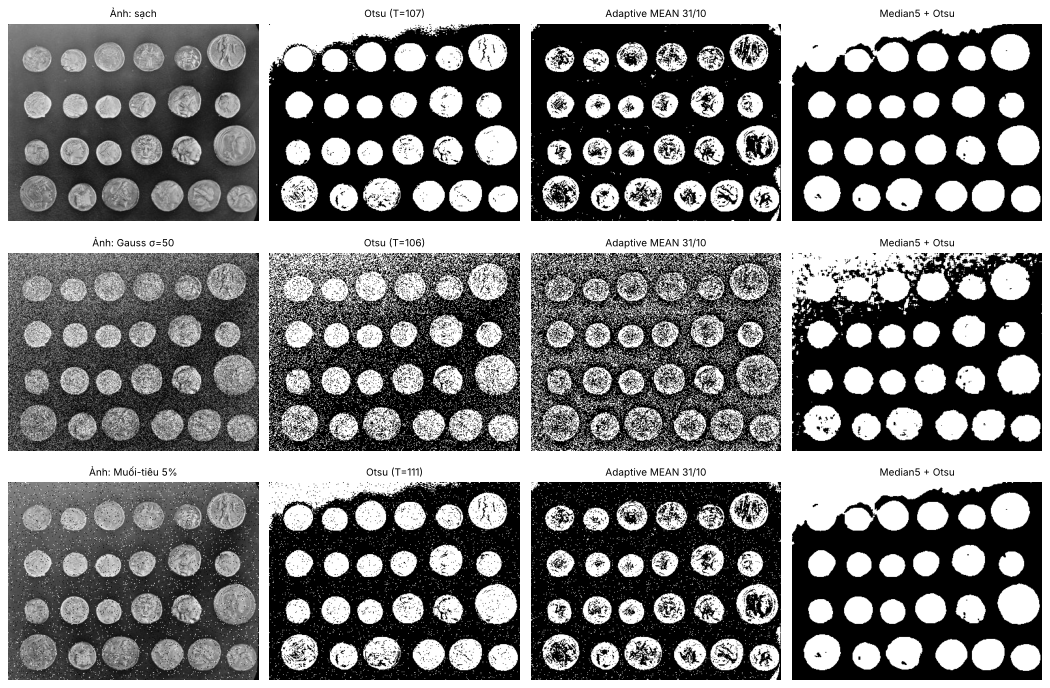

In [12]:
t0, _ = otsu_threshold(coins)
ref_mask = cv2.threshold(coins, t0, 255, cv2.THRESH_BINARY)[1] > 0
def dice(a, b):
    return 2 * (a & b).sum() / max(a.sum() + b.sum(), 1)

methods = {
    "Otsu":                 lambda im: cv2.threshold(im, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU),
    "Adaptive MEAN 31/10":  lambda im: (None, cv2.adaptiveThreshold(im, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 31, -10)),
    "Median5 + Otsu":       lambda im: cv2.threshold(cv2.medianBlur(im, 5), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU),
    "Gauss5 + Otsu":        lambda im: cv2.threshold(cv2.GaussianBlur(im, (5, 5), 0), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU),
}
noisy_coins = {k: fn(coins) for k, fn in noises.items()}
print(f"Ngưỡng Otsu ảnh sạch = {t0}\n")
print(f"{'nhiễu':14s} " + " ".join(f"{m:>22s}" for m in methods) + "   (Dice so với mặt nạ Otsu ảnh sạch)")
dice_rows = {}
for nk, nim in noisy_coins.items():
    vals, ts = [], []
    for mn, mf in methods.items():
        t, b = mf(nim)
        vals.append(dice(b > 0, ref_mask)); ts.append(t)
    dice_rows[nk] = vals
    print(f"{nk:14s} " + " ".join(f"{v:22.3f}" for v in vals) + f"   T_Otsu(thô) = {int(ts[0])}")
sel = ["sạch", "Gauss σ=50", "Muối-tiêu 5%"]
imgs, tits = [], []
for nk in sel:
    nim = noisy_coins[nk]
    imgs += [nim, methods["Otsu"](nim)[1], methods["Adaptive MEAN 31/10"](nim)[1], methods["Median5 + Otsu"](nim)[1]]
    tits += [f"Ảnh: {nk}", f"Otsu (T={int(methods['Otsu'](nim)[0])})", "Adaptive MEAN 31/10", "Median5 + Otsu"]
show(imgs, tits, ncols=4, cell=3.3, name="b3_noise_thresh.png")

**Nhận xét 3.3** (biên tham chiếu = Canny σ=1, 50/150 của ảnh sạch, nên F1 chỉ mang tính so sánh tương đối, không phải ground-truth do người vẽ)
* **Phát hiện biên:** Sobel (ngưỡng 20% max cố định) có số điểm biên tăng 14 503 -> 36 478 (Gauss σ=25) -> 104 008 (σ=50) và F1 giảm 0,87 -> 0,58 -> 0,30, vì nhiễu làm gradient tăng trên toàn ảnh. Canny **không làm trơn** là kém nhất: ngay với σ_n = 10 số điểm biên tăng 30 980 -> 54 396 và F1 xuống 0,33; với σ_n = 25 chỉ còn 0,21 (biên thật bị chìm trong biên giả). Canny σ = 1,5 bền nhất với nhiễu Gauss (F1 0,81 -> 0,82 -> 0,66 ở σ_n = 0/25/50); Gauss 5×5 + Canny tốt nhất khi ảnh sạch (0,94) nhưng giảm nhanh hơn khi nhiễu mạnh (0,23 ở σ_n = 50).
* **Nhiễu muối-tiêu:** làm trơn Gauss không hiệu quả (F1 chỉ 0,42 ở 5%) vì nó lan điểm nhiễu thành đốm nhỏ; **median 5×5 + Canny** gần như không bị ảnh hưởng (F1 0,84 ở cả 0% và 5%) vì median loại điểm ngoại lai mà không làm nhòe biên. Với nhiễu Gauss, median 5×5 cũng không kém Gauss 5×5 (σ_n = 25: 0,75 so với 0,62; σ_n = 50: 0,26 so với 0,23, cả hai đều thấp) nhưng thua ở ảnh sạch (0,84 so với 0,94). **Chọn bộ lọc khử nhiễu theo loại nhiễu** là điều quan trọng nhất.
* **Phân ngưỡng** (Dice so với mặt nạ Otsu của ảnh sạch): ngưỡng Otsu T gần như không đổi (106 - 111 so với 107) nhưng chất lượng giảm vì nhiễu làm *mỗi lớp xuất hiện pixel thuộc lớp kia*: Otsu Dice 0,95 / 0,88 / 0,75 với Gauss σ_n = 10 / 25 / 50 và 0,98 / 0,95 với muối-tiêu 2% / 5%. Khử nhiễu trước (median hoặc Gauss 5×5) giữ Dice ≥ 0,91 ở σ_n = 50 và ≥ 0,94 với muối-tiêu 5% (median 0,96), dù ảnh sạch chỉ đạt 0,96 - 0,97 vì làm trơn làm lệch nhẹ đường biên. Adaptive MEAN 31/10 kém nhất (0,78 ở ảnh sạch, 0,60 ở σ_n = 50) vì cửa sổ nhỏ bám theo nhiễu.